In [ ]:
# install dependencies and make a conda environment for gromacs
# update conda if needed: conda install -n base -c conda-forge --override-channels conda-libmamba-solver
# i had to install a specific build of gromacs that has cuda support or else it defaults to openCL
# conda create -n gromacs-cuda -c conda-forge "gromacs=2026.3=nompi_cuda*" ipykernel matplotlib mdtraj pdb2pqr nglview
# conda activate gromacs-cuda

# verify gromacs installation
!gmx -version

# verify that your gpu can be recognized
!nvidia-smi

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph
Command line:
  gmx -version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/

In [ ]:
# prepare the pdb file, first protonating using propka
# make sure you're launching vscode with code . when you're in the directory you want to work in

!pdb2pqr --ff=AMBER --titration-state-method=propka --with-ph=7.4 pvivax-6pgdh-dimer-relaxed.pdb --ffout=AMBER pvivax-6pgdh-dimer-relaxed_pH7-4.pdb

In [51]:
# if you want to remove any ligands or water molecules, run !grep -v HETATM protein.pdb > protein_clean.pdb
# view structure of the protein before proceeding
import nglview
print(nglview.__version__)
view = nglview.show_structure_file("pvivax-6pgdh-dimer-relaxed_pH7-4.pdb")
view

4.0.1


NGLWidget()

In [ ]:
# protonated residue names like HID from pdb2pqr are not recognized by gromacs
# rename using python to CHARMM36 standard residue names
# here are the charmm residue names https://charmm-gui.org/?doc=archive&lib=csml
# original protonated residue names used by propka https://software.acellera.com/htmd/tutorials/protein-preparation.html

rename = {"HID": "HSD ", "HIE": "HSE ", "HIP": "HSP ",
          "ASH": "ASPP", "GLH": "GLUP", "LYN": "LSN ", "CYX": "CYS "}

n = {}
with open("pvivax-6pgdh-dimer-relaxed_pH7-4.pdb") as f, open("pvivax-6pgdh-dimer_renamed.pdb", "w") as g:
    for line in f:
        if line.startswith(("ATOM", "HETATM")) and line[17:20] in rename:
            n[line[17:20]] = n.get(line[17:20], 0) + 1
            line = line[:17] + rename[line[17:20]] + line[21:]
        g.write(line)
print(n)

{'HID': 204, 'GLH': 32, 'HIE': 34, 'ASH': 26}


In [ ]:
# generate topology files for the protein using gmx pdb2gmx
# using charmm36m which isn't shipped with gromacs automatically
# download from https://mackerell.umaryland.edu/charmm_ff.shtml#gromacs and put it in your working directory
# then extract with tar -xf charmm36-feb2026_cgenff-5.0.ff.tgz

!gmx pdb2gmx -f pvivax-6pgdh-dimer_renamed.pdb -o pvivax-6pgdh-dimer_processed.gro -ignh -chainsep ter -ter -water tip3p 

# this pulls up a menu to select the force field, so pick the one corresponding to CHARMM36m
# it also asks you for the N and C terminal protonation states, so pick the one corresponding to your pH (NTER=NH3+, CTER=COO- for pH 7.4)

               :-) GROMACS - gmx pdb2gmx, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx pdb2gmx -f pvivax-6pgdh-dimer_renamed.pdb -o pvivax-6pgdh-dimer_processed.gro -water tip3p

Note that more recent versions of the CHARMM force field may be downloaded from
http://mackerell.umaryland.edu/charmm_ff.shtml#gromacs.

Select the Force Field:

From current directory:

 1: CHARMM all-atom force field

From '/home/morph/miniconda3/envs/gromacs-cuda/share/gromacs/top':

 2: AMBER03 protein, nucleic AMBER94 (Duan et al., J. Comp. Chem. 24, 1999-2012, 2003)

 3: AMBER14SB protein (Maier, J. A. et al. JCTC 11, 3696–3713, 2015 / Miletic, V. et al. ChemRxiv, 2026)

 4: AMBER19SB protein (Tian, C. et al. JCTC 16, 528–552, 2020 / Miletic, V. et al. ChemRxiv, 2026)

 5: AMBER94 force field (Cornell et al., JACS 117, 5179-5197, 1995)

 6: AMBER9

In [ ]:
# inspect the files that were just generated
!head -30 topol.top

;
;	File 'topol.top' was generated
;	By user: unknown (1000)
;	On host: morph
;	At date: Sun Nov  8 13:20:18 2026
;
;	This is a standalone topology file
;
;	Created by:
;	              :-) GROMACS - gmx pdb2gmx, 2026.3-conda_forge (-:
;	
;	Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
;	Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
;	Working dir:  /home/morph/gromacs
;	Command line:
;	  gmx pdb2gmx -f pvivax-6pgdh-dimer_renamed.pdb -o pvivax-6pgdh-dimer_processed.gro -ignh -chainsep ter -ter -water tip3p
;	Force field was read from current directory or a relative path - path added.
;

; Include forcefield parameters
#include "./charmm36-feb2026_cgenff-5.0.ff/forcefield.itp"

; Include chain topologies
#include "topol_Protein.itp"
#include "topol_Protein2.itp"

; Include water topology
#include "./charmm36-feb2026_cgenff-5.0.ff/tip3p.itp"

#ifdef POSRES_WATER


In [18]:
# inspect protein file as well, looking at atom types, charge, mass, bonds etc
!grep "atoms" -A 7 topol_Protein.itp
!grep "bonds" -A 7 topol_Protein.itp
!grep "water topology" -A 8 topol.top

[ atoms ]
;   nr       type  resnr residue  atom   cgnr     charge       mass  typeB    chargeB      massB
; residue   1 MET rtp MET  q +1.0
     1        NH3      1    MET      N      1       -0.3     14.007
     2         HC      1    MET     H1      2       0.33      1.008
     3         HC      1    MET     H2      3       0.33      1.008
     4         HC      1    MET     H3      4       0.33      1.008
     5        CT1      1    MET     CA      5       0.21     12.011
[ bonds ]
;  ai    aj funct            c0            c1            c2            c3
    1     2     1 
    1     3     1 
    1     4     1 
    1     5     1 
    5     6     1 
    5     7     1 
; Include water topology
#include "./charmm36-feb2026_cgenff-5.0.ff/tip3p.itp"

#ifdef POSRES_WATER
; Position restraint for each water oxygen
[ position_restraints ]
;  i funct       fcx        fcy        fcz
   1    1       1000       1000       1000
#endif


In [19]:
# define the simulation box, creating a rhomic dodecahedron box with 1.0 nm distance from the protein to the box edge
!gmx editconf -f pvivax-6pgdh-dimer_processed.gro -o pvivax-6pgdh-dimer_newbox.gro -c -d 1.0 -bt dodecahedron

cat: write error: Broken pipe
               :-) GROMACS - gmx editconf, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx editconf -f pvivax-6pgdh-dimer_processed.gro -o pvivax-6pgdh-dimer_newbox.gro -c -d 1.0 -bt dodecahedron

Note that major changes are planned in future for editconf, to improve usability and utility.
Read 15054 atoms
Volume: 541.137 nm^3, corresponds to roughly 243500 electrons
No velocities found
    system size :  7.820  8.955  7.728 (nm)
    diameter    : 10.253               (nm)
    center      : -0.059 -0.017 -0.005 (nm)
    box vectors :  7.820  8.956  7.727 (nm)
    box angles  :  90.00  90.00  90.00 (degrees)
    box volume  : 541.14               (nm^3)
    shift       :  9.249  9.207  4.338 (nm)
new center      :  9.190  9.190  4.332 (nm)
new box vectors : 12.253 12.253 12.253 (nm)
new box angles  :  6

In [20]:
# check to make sure the newbox.gro file looks fine
!head -2 pvivax-6pgdh-dimer_newbox.gro
!tail -1 pvivax-6pgdh-dimer_newbox.gro
!gmx check -f pvivax-6pgdh-dimer_newbox.gro

S  C  A  M  O  R  G
15054
  12.25330  12.25330   8.66439   0.00000   0.00000   0.00000   0.00000   6.12665   6.12665
                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx check -f pvivax-6pgdh-dimer_newbox.gro

Checking file pvivax-6pgdh-dimer_newbox.gro
Reading frames from gro file 'S  C  A  M  O  R  G', 15054 atoms.
Reading frame       0 time    0.000   
# Atoms  15054
Precision 0.001 (nm)
Last frame          0 time    0.000   


Item        #frames Timestep (ps)
Step             0
Time             0
Lambda           0
Coords           1
Velocities       0
Forces           0
Box              1

GROMACS reminds you: "Should we force science down the throats of those that have no taste for it? Is it our duty to drag them kicking and screaming into the twenty-first century? I am afraid that it is."

In [ ]:
# solvate with water molecules
# tip3p is a 3 point water model so it is compatible with spc216.gro even though they don't have the same name
!gmx solvate -cp pvivax-6pgdh-dimer_newbox.gro -cs spc216.gro -o pvivax-6pgdh-dimer_solv.gro -p topol.top
# this tells you how many water molecules are present
!tail topol.top

               :-) GROMACS - gmx solvate, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx solvate -cp pvivax-6pgdh-dimer_newbox.gro -cs spc216.gro -o pvivax-6pgdh-dimer_solv.gro -p topol.top

Reading solute configuration
Reading solvent configuration

Initialising inter-atomic distances...

         based on residue and atom names, since they could not be
         definitively assigned from the information in your input
         files. These guessed numbers might deviate from the mass
         and radius of the atom type. Please check the output
         files if necessary. Note, that this functionality may
         be removed in a future GROMACS version. Please, consider
         using another file format for your input.

         The atomic radii are set according to:

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
A. Bon

In [50]:
# visualize solvated system
# note for some reason nglview doesn't properly show dodecahedrons properly so i had to convert into a cubic box for visualization purposes
# this is obviously not exactly what the box looks like
!touch viz.mdp
!gmx grompp -f viz.mdp -c pvivax-6pgdh-dimer_solv.gro -p topol.top -o viz.tpr
!printf "0\n" | gmx trjconv -f pvivax-6pgdh-dimer_solv.gro -s viz.tpr -o pvivax-6pgdh-dimer_solv-viz.gro -pbc mol -ur compact
view = nglview.show_structure_file("pvivax-6pgdh-dimer_solv-viz.gro")
view.add_representation(repr_type='ball+stick', selection='SOL')
view.camera = 'orthographic'
view
view.render_image()
view._display_image()

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx grompp -f viz.mdp -c pvivax-6pgdh-dimer_solv.gro -p topol.top -o viz.tpr


NOTE 1 [file viz.mdp]:
  For a correct single-point energy evaluation with nsteps = 0, use
  continuation = yes to avoid constraining the input coordinates.

Setting the LD random seed to -1345683667

Generated 169542 of the 169653 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 1

Generated 118878 of the 169653 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

Excluding 3 bonded neighbours molecule type 'Protein2'

Excluding 2 bonded neighbours molecule type 'SOL'

Excluding 3 bonded neighbours molecule type 'NA'

Excluding 3 bonded neighbours molecule type 'CL'

---------------------------------------------------

In [24]:
# to add ions i'm going to use gmx genion
# create a blank .mdp file first
!touch ions.mdp
# then use grompp to assemble a tpr file for genion to use
!gmx grompp -f ions.mdp -c pvivax-6pgdh-dimer_solv.gro -p topol.top -o ions.tpr

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx grompp -f ions.mdp -c pvivax-6pgdh-dimer_solv.gro -p topol.top -o ions.tpr


NOTE 1 [file ions.mdp]:
  For a correct single-point energy evaluation with nsteps = 0, use
  continuation = yes to avoid constraining the input coordinates.

Setting the LD random seed to -82903233

Generated 169542 of the 169653 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 1

Generated 118878 of the 169653 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

Excluding 3 bonded neighbours molecule type 'Protein2'

Excluding 2 bonded neighbours molecule type 'SOL'

Taking velocities from 'pvivax-6pgdh-dimer_solv.gro', all velocities are zero

NOTE 2 [file topol.top, line 48]:
  The bond in molecule-type Protein b

In [25]:
# use gromacs genion to add ions at a final concentration of 0.15 M and also neutralizing the charge
# only run this once, because it edits the topology you have already made
# if you accidentally run it more than once, start over at the gmx pdb2gmx step
!printf "SOL\n" | gmx genion -s ions.tpr -o pvivax-6pgdh-dimer_solv_ions.gro -p topol.top -pname NA -nname CL -neutral -conc 0.15

                :-) GROMACS - gmx genion, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx genion -s ions.tpr -o pvivax-6pgdh-dimer_solv_ions.gro -p topol.top -pname NA -nname CL -neutral -conc 0.15

Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Will try to add 118 NA ions and 118 CL ions.
Select a continuous group of solvent molecules
Group     0 (         System) has 129495 elements
Group     1 (        Protein) has 15054 elements
Group     2 (      Protein-H) has  7492 elements
Group     3 (        C-alpha) has   946 elements
Group     4 (       Backbone) has  2838 elements
Group     5 (      MainChain) has  3782 elements
Group     6 (   MainChain+Cb) has  4654 elements
Group     7 (    MainChain+H) has  4708 elements
Group     8 (      Si

In [29]:
# check charge of the protein
!grep "bonds" -B 10 topol_Protein.itp
# verify the ions were added
!tail topol.top

  7519        CT2    473    GLU     CG   7519      -0.28     12.011
  7520        HA2    473    GLU    HG1   7520       0.09      1.008
  7521        HA2    473    GLU    HG2   7521       0.09      1.008
  7522         CC    473    GLU     CD   7522       0.62     12.011
  7523         OC    473    GLU    OE1   7523      -0.76    15.9994
  7524         OC    473    GLU    OE2   7524      -0.76    15.9994
  7525         CC    473    GLU      C   7525       0.34     12.011
  7526         OC    473    GLU    OT1   7526      -0.67    15.9994
  7527         OC    473    GLU    OT2   7527      -0.67    15.9994   ; qtot 0

[ bonds ]
; Name
Protein in water

[ molecules ]
; Compound        #mols
Protein             1
Protein2            1
SOL         37911
NA               118
CL               118


In [ ]:
# for energy minimization you need an .mdp file with parameters set
# you can also just write it using python
# i started with the default emin file from a tutorial then modified it
# i took some of the settings from https://github.com/MobleyLab/FreeSolv/blob/master/gromacs_mdpfiles/DH_mdp/in_solution/minimize.mdp

%%writefile emin-charmm.mdp
title       = CHARMM steepest descent energy minimisation

; Parameters describing what to do, when to stop and what to save
integrator  = steep  ; Algorithm (steep = steepest descent minimization)
emtol       = 1000.0 ; Stop minimization when the maximum force < 1000.0 kJ/mol/nm
emstep      = 0.001   ; Minimization step size, was 0.01 but made it smaller to be safer for solvated systems
nstlog		= 100
nstenergy   = 100    ; energy output interval
nsteps      = 50000     ; run for 50k steps

; Neighbor searching parameters
nstlist                  = 10
ns_type                  = grid
pbc                      = xyz
rlist                    = 1.2

; Settings that make sure we run with parameters in harmony with the selected force-field
constraints             = h-bonds   ; bonds involving H are constrained
constraint-algorithm    = Lincs		; use LINCS to constrain h bonds
rcoulomb                = 1.2       ; short-range electrostatic cutoff (in nm)
rvdw                    = 1.2       ; short-range van der Waals cutoff (in nm)
vdw-modifier            = Force-switch ;  specific CHARMM
rvdw_switch             = 1.0       ;
DispCorr                = no        ; account for cut-off vdW scheme -

;in case of CHARMM DispCorr = EnerPres only for monolayers
coulombtype             = PME       ; Particle Mesh Ewald for long-range electrostatics
pme-order               = 4			; cubic interpolation
fourierspacing          = 0.12     ; grid spacing for FFT, lowered from 0.15

In [30]:
# use grompp to prepare files for energy minimization
!gmx grompp -f emin-charmm.mdp -c pvivax-6pgdh-dimer_solv_ions.gro -p topol.top -o em.tpr

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx grompp -f emin-charmm.mdp -c pvivax-6pgdh-dimer_solv_ions.gro -p topol.top -o em.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'
Setting the LD random seed to -362116149

Generated 169542 of the 169653 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 1

Generated 118878 of the 169653 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein2'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 3 bonded neighbou

In [ ]:
# use gmx mdrun to execute energy minimization
# use multithreading and gpu acceleration
# -v is the verbose flag to show simulation progress
# ntmpi is the number of MPI ranks, ntomp is the number of OpenMP threads per rank, and -nb gpu tells gromacs to use the GPU
!gmx mdrun -v -deffnm em -ntmpi 1 -ntomp 10 -nb gpu

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx mdrun -v -deffnm em -ntmpi 1 -ntomp 10 -nb gpu


Back Off! I just backed up em.log to ./#em.log.1#
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file em.tpr, VERSION 2026.3-conda_forge (single precision)

1 GPU selected for this run.
Mapping of GPU IDs to the 1 GPU task in the 1 rank on this node:
  PP:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
Using 1 MPI thread
Using 10 OpenMP threads 


NOTE: The number of threads is not equal to 

                :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx energy -f em.edr -o potential.xvg -xvg none

Opened em.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  U-B              3  Proper-Dih.      4  Improper-Dih. 
  5  CMAP-Dih.        6  LJ-14            7  Coulomb-14       8  LJ-(SR)       
  9  Coulomb-(SR)    10  Coul.-recip.    11  Potential       12  Pressure      
 13  Constr.-rmsd    14  Vir-XX          15  Vir-XY          16  Vir-XZ        
 17  Vir-YX          18  Vir-YY          19  Vir-YZ          20  Vir-ZX        
 21  Vir-ZY          22

<Axes: title={'center': 'Potential energy during energy minimisation'}, xlabel='Step', ylabel='Potential energy (kJ/mol)'>

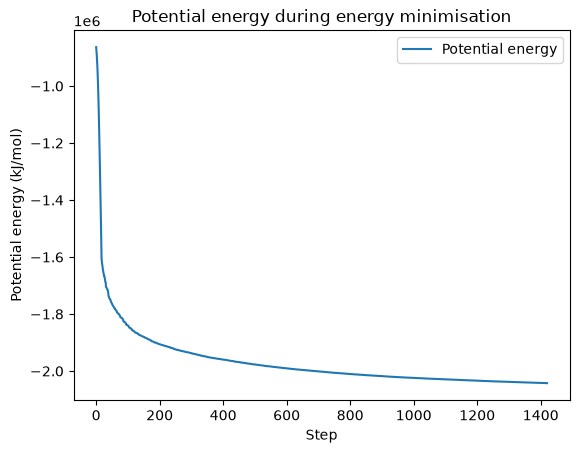

In [35]:
# plot to confirm energy minimization
!printf "Potential\n0\n" | gmx energy -f em.edr -o potential.xvg -xvg none
import pandas as pd
df = pd.read_csv('potential.xvg', sep='\\s+', header=None, names=['Potential energy'])
df.plot(xlabel = 'Step', ylabel = 'Potential energy (kJ/mol)', title = "Potential energy during energy minimisation")

In [ ]:
# now that we've minimized the system, we need to equilibrate it before running production MD
# equilibration happens in two steps: NVT (isothermal-isochoric) and NPT
# prepare the nvt-charmm.mdp file
# note that you need to include -DPOSRES which restrains heavy atoms, allowing solvent to equilibrate around it
# i used the default from the tutorial but also included a gradual heating step from 0 to 300 K so as not to shock the system

%%writefile nvt-charmm.mdp
title                   = CHARMM NVT equilibration 
define                  = -DPOSRES  ; position restrain the protein

; Parameters describing what to do, when to stop and what to save
integrator              = md        ; leap-frog integrator
dt                      = 0.002     ; 2 fs
continuation            = no		; due to lack of existing constraints on coordinates
nstenergy               = 500       ; save energy and temperature every 1.0 ps

; periodic boundary condition
cutoff-scheme           = Verlet
pbc                     = xyz       
nstlist                 = 10

; Keep system temperature fluctuating physically correct
tcoupl                  = V-rescale           ; modified Berendsen thermostat
ld-seed					= 13		; set langevin dynamics random seed for reproducibility
tc-grps                 = system   ; coupling groups 
tau_t                   = 1      ; time constant, in ps
ref_t                   = 300      ; reference temperature, one for each group, in K

; Pressure coupling is off
pcoupl                  = no

; Velocity generation
gen-vel                 = yes
gen-temp                = 0
annealing               = single
annealing-npoints       = 2
annealing-time          = 0 400       ; ps
annealing-temp          = 0 300       ; K
nsteps                  = 250000      ; 500 ps so it holds at 300 K after the ramp

; Settings that make sure we run with parameters in harmony with the selected force-field
constraints             = h-bonds   ; bonds involving H are constrained
rcoulomb                = 1.2       ; short-range electrostatic cutoff (in nm)
rvdw                    = 1.2       ; short-range van der Waals cutoff (in nm)
vdw-modifier            = Force-switch ;  specific CHARMM
rvdw_switch             = 1.0       ;
DispCorr                = no        ; account for cut-off vdW scheme -
;in case of CHARMM DispCorr = EnerPres only for monolayers
coulombtype             = PME       ; Particle Mesh Ewald for long-range electrostatics
fourierspacing          = 0.15     ; grid spacing for FFT

In [37]:
# NVT equilibration, gradually heating system from 0 to 300 K, restraints on heavy atoms, constraints on h bonds

!gmx grompp -f nvt-charmm.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr
!gmx mdrun -v -deffnm nvt -ntmpi 1 -ntomp 10 -nb gpu

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx grompp -f nvt-charmm.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr

Ignoring obsolete mdp entry 'title'
Generated 169542 of the 169653 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 1

Generated 118878 of the 169653 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein2'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Setting gen_seed to -426975809

Velo

                :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx energy -f nvt.edr -o temperature.xvg -xvg none -b 20

Opened nvt.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  U-B              3  Proper-Dih.      4  Improper-Dih. 
  5  CMAP-Dih.        6  LJ-14            7  Coulomb-14       8  LJ-(SR)       
  9  Coulomb-(SR)    10  Coul.-recip.    11  Position-Rest.  12  Potential     
 13  Kinetic-En.     14  Total-Energy    15  Conserved-En.   16  Temperature   
 17  Pressure        18  Constr.-rmsd    19  Vir-XX          20  Vir-XY        
 21  Vir-XZ  

<Axes: title={'center': 'Temperature during NVT equilibration'}, xlabel='Time (ps)', ylabel='Temperature (K)'>

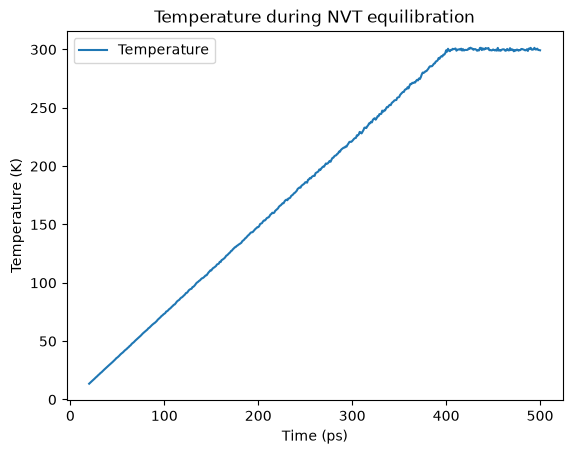

In [38]:
# verify that temperature is stable for the NVT simulation
!echo "Temperature" | gmx energy -f nvt.edr -o temperature.xvg -xvg none -b 20
df = pd.read_csv('temperature.xvg', sep='\\s+', header=None, names=['Temperature'])
df.plot(xlabel = 'Time (ps)', ylabel = 'Temperature (K)', title = "Temperature during NVT equilibration")

In [ ]:
# prepare the npt-charmm.mdp file

%%writefile npt-charmm.mdp
title                   = CHARMM NPT equilibration 
define                  = -DPOSRES  ; position restrain the protein 

; Parameters describing what to do, when to stop and what to save
integrator              = md        ; leap-frog integrator
dt                      = 0.002     ; 2 fs
nsteps                  = 250000     ; 500 ps equilibration. increased from 100 ps due to size of system.
nstenergy               = 500       ; save energy and temperature every 1.0 ps
nstlog                  = 500
gen-vel                 = no        ; because we are continuing from NVT equilibration

; periodic boundary condition
cutoff-scheme           = Verlet    ; default but just putting this here to be explicit
pbc                     = xyz
continuation            = yes      ; again because continuing from NVT
nstlist                 = 10
nstxout-compressed      = 5000      ; saves trajectory

; Pressure coupling is on
pcoupl                  = C-rescale             ; Pressure coupling on in NPT
pcoupltype              = isotropic             ; uniform scaling of box vectors
tau_p                   = 2.0                   ; time constant, in ps. reduced from 5 to 2 to make it more responsive to fluctuations
ref_p                   = 1.0                   ; reference pressure, in bar
compressibility         = 4.5e-5                ; isothermal compressibility of water, bar^-1
refcoord_scaling        = com

; Keep system temperature fluctuating physically correct
tcoupl                  = V-rescale           ; modified Berendsen thermostat
ld-seed					= 13        ; same random seed as NVT
tc-grps                 = system   ; coupling groups 
tau_t                   = 1.0      ; time constant, in ps
ref_t                   = 300      ; reference temperature, one for each group, in K

; Settings that make sure we run with parameters in harmony with the selected force-field
constraints             = h-bonds   ; bonds involving H are constrained
constraint-algorithm    = lincs     ; same as NVT
rcoulomb                = 1.2       ; short-range electrostatic cutoff (in nm)
rvdw                    = 1.2       ; short-range van der Waals cutoff (in nm)
vdw-modifier            = Force-switch ;  specific CHARMM
rvdw_switch             = 1.0       ;
DispCorr                = no        ; account for cut-off vdW scheme -
;in case of CHARMM DispCorr = EnerPres only for monolayers
coulombtype             = PME       ; Particle Mesh Ewald for long-range electrostatics
fourierspacing          = 0.12     ; grid spacing for FFT

In [41]:
# prepare files for the NPT simulation
!gmx grompp -f npt-charmm.mdp -c nvt.gro -r nvt.gro -t nvt.cpt -p topol.top -o npt.tpr

cat: write error: Broken pipe
                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx grompp -f npt-charmm.mdp -c nvt.gro -r nvt.gro -t nvt.cpt -p topol.top -o npt.tpr

Ignoring obsolete mdp entry 'title'
Generated 169542 of the 169653 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 1

Generated 118878 of the 169653 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein2'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'CL'

turning H bonds into constrain

In [42]:
# actually run the NPT simulation
!gmx mdrun -v -deffnm npt -ntmpi 1 -ntomp 10 -nb gpu

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx mdrun -v -deffnm npt -ntmpi 1 -ntomp 10 -nb gpu

The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file npt.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 10 to 100, rlist from 1.2 to 1.363


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on the GPU
PME tasks will do all aspects on the GPU
Using 1 MPI thread
Using 10 OpenM

                :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx energy -f npt.edr -o density.xvg -xvg none

Opened npt.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  U-B              3  Proper-Dih.      4  Improper-Dih. 
  5  CMAP-Dih.        6  LJ-14            7  Coulomb-14       8  LJ-(SR)       
  9  Coulomb-(SR)    10  Coul.-recip.    11  Position-Rest.  12  Potential     
 13  Kinetic-En.     14  Total-Energy    15  Conserved-En.   16  Temperature   
 17  Pressure        18  Constr.-rmsd    19  Box-X           20  Box-Y         
 21  Box-Z           22

<Axes: title={'center': 'Density during NPT equilibration'}, xlabel='Time (ps)', ylabel='Density (kg/m^3)'>

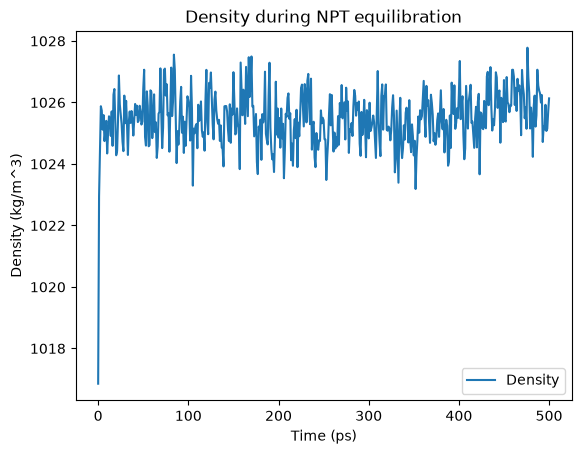

In [ ]:
# during an NPT simulation the pressure fluctuates wildly even though the average is 1 bar
# more informative to look at density which should stabilize
# it should be slightly higher than 1000 kg/m^3 due to the presence of the protein

!echo "Density" | gmx energy -f npt.edr -o density.xvg -xvg none
df = pd.read_csv('density.xvg', sep='\\s+', header=None, names=['Density'])
df.plot(xlabel = 'Time (ps)', ylabel = 'Density (kg/m^3)', title = "Density during NPT equilibration")

In [ ]:
# last step, prepare the production MD simulation by making the md-charmm.mdp file

%%writefile md-charmm.mdp
; Parameters describing what to do, when to stop and what to save
integrator              = md        ; leap-frog integrator
dt                      = 0.002     ; 2 fs
nsteps                  = 500000     ;  this is for 1 ns because it is 1000 ps (.002*500000). increase to 100 ns or more when ready
continuation            = yes
gen-vel                 = no

; periodic boundary condition
cutoff-scheme           = Verlet
pbc                     = xyz
nstlist                 = 10

; Output control - output frequency in steps
; Output frequency for  output trajctory file ,trr
nstxout                  = 0       ; for writing coords (x) 
nstvout                  = 0       ; for writing velocities (v) 
nstfout                  = 0       ; for writing forces (f) 
; Output frequency for energies to log file and energy file
nstlog                   = 5000    ; for writing energies to log file
nstenergy                = 5000    ; for writing energies to edr file 
nstcalcenergy            = 100
; Output frequency and precision for .xtc file
nstxout-compressed       = 5000    ; writes one frame per 10 ps

; Pressure coupling is on
pcoupl                  = C-rescale               ; Pressure coupling on in NPT
pcoupltype              = isotropic             ; uniform scaling of box vectors
tau_p                   = 2.0                   ; time constant, in ps
ref_p                   = 1.0                   ; reference pressure, in bar
compressibility         = 4.5e-5                ; isothermal compressibility of water, bar^-1
refcoord_scaling        = com

; Keep system temperature fluctuating physically correct
tcoupl                  = V-rescale           ; modified Berendsen thermostat
ld-seed					= 13	 ; same as for NVT and NPT equilibration
tc-grps                 = system ; 
tau_t                   = 1.0    ; time constant, in ps
ref_t                   = 300    ; reference temperature, one for each group, in K

; Settings that make sure we run with parameters in harmony with the selected force-field
constraints             = h-bonds   ; bonds involving H are constrained
constraint-algorithm    = lincs		; same as for NVT and NPT
rcoulomb                = 1.2       ; short-range electrostatic cutoff (in nm)
rvdw                    = 1.2       ; short-range van der Waals cutoff (in nm)
vdw-modifier            = Force-switch ;  specific CHARMM
rvdw_switch             = 1.0       ;
DispCorr                = no        ; account for cut-off vdW scheme -
;in case of CHARMM DispCorr = EnerPres only for monolayers
coulombtype             = PME       ; Particle Mesh Ewald for long-range electrostatics
fourierspacing          = 0.12     ; grid spacing for FFT, like earlier files

In [55]:
# prepare production MD run files
!gmx grompp -f md-charmm.mdp -c npt.gro -t npt.cpt -p topol.top -o md.tpr

cat: write error: Broken pipe
                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /home/morph/miniconda3/envs/gromacs-cuda/bin.AVX2_256/gmx
Data prefix:  /home/morph/miniconda3/envs/gromacs-cuda
Working dir:  /home/morph/gromacs
Command line:
  gmx grompp -f md-charmm.mdp -c npt.gro -t npt.cpt -p topol.top -o md.tpr

Generated 169542 of the 169653 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 1

Generated 118878 of the 169653 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein2'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Taking velocities from 'npt.gro'
Analysing

In [ ]:
# execute the production MD run
!gmx mdrun -v -deffnm md -ntmpi 1 -ntomp 10